Parámetro de Hurst (H) para capture1.csv: 0.827
Parámetro de Hurst (H) para capture2.csv: 0.740
Parámetro de Hurst (H) para capture3.csv: 0.804


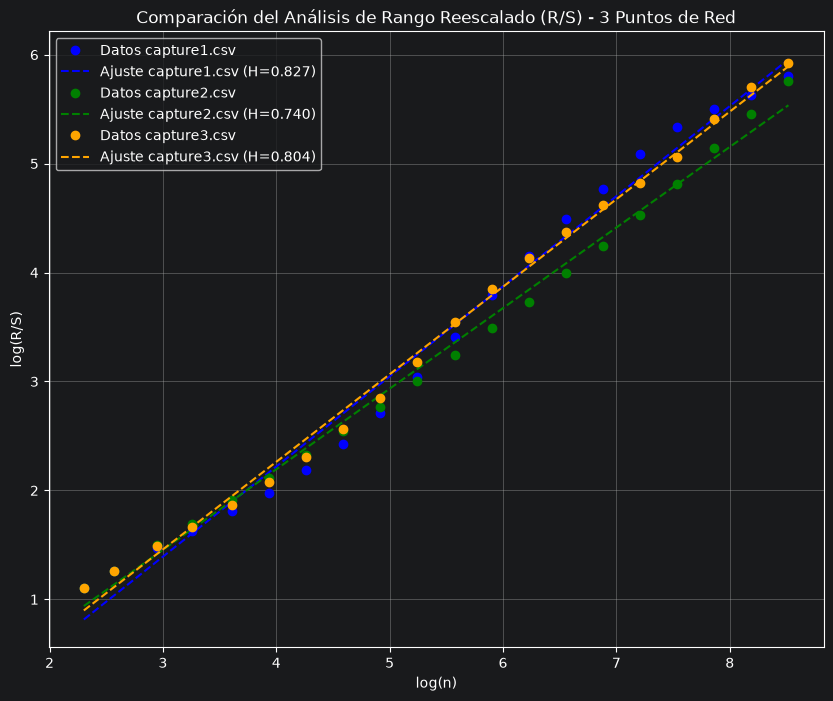

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Lista de los tres archivos a procesar
archivos = ['capture1.csv', 'capture2.csv', 'capture3.csv']
colores = ['blue', 'green', 'orange']

plt.figure(figsize=(10, 8))

def rs_plot(data, max_n):
    n_values = np.logspace(1, np.log10(max_n), 20).astype(int)
    rs_values = []

    for n in n_values:
        blocks = np.array_split(data, len(data)//n)
        rs_list = []
        for block in blocks:
            mean = np.mean(block)
            Y = np.cumsum(block - mean)
            R = np.max(Y) - np.min(Y)
            S = np.std(block)

            if S > 0:
                rs_list.append(R/S)
        rs_values.append(np.mean(rs_list))
    return n_values, rs_values

# Procesar y comparar cada archivo
for i, archivo in enumerate(archivos):
    try:
        # El parámetro on_bad_lines='skip' evita el ParserError saltando las filas conflictivas
        df = pd.read_csv(archivo, on_bad_lines='skip', engine='python')

        # Detección automática del formato de columnas
        if 'frame.time_epoch' in df.columns:
            timestamps = df['frame.time_epoch'].values
        elif 'Time' in df.columns:
            timestamps = df['Time'].values
        else:
            print(f"Omitiendo {archivo}: Formato de columnas no reconocido.")
            continue

        # Calcular los Inter-Arrival Times (IAT) en milisegundos
        # Eliminamos posibles valores nulos (NaN) causados por filas saltadas
        timestamps = timestamps[~np.isnan(timestamps)]
        IAT = np.diff(timestamps) * 1000

        # Ejecutar análisis R/S
        n_vals, rs_vals = rs_plot(IAT, max_n=5000)

        # Calcular el parámetro de Hurst (H)
        H_real = np.polyfit(np.log(n_vals), np.log(rs_vals), 1)[0]
        print(f"Parámetro de Hurst (H) para {archivo}: {H_real:.3f}")

        # Agregar al gráfico comparativo
        plt.plot(np.log(n_vals), np.log(rs_vals), marker='o', linestyle='', color=colores[i], label=f'Datos {archivo}')
        plt.plot(np.log(n_vals), np.polyval(np.polyfit(np.log(n_vals), np.log(rs_vals), 1), np.log(n_vals)), color=colores[i], linestyle='--', label=f'Ajuste {archivo} (H={H_real:.3f})')

    except FileNotFoundError:
        print(f"Error: El archivo {archivo} no se encontró en el directorio.")
    except Exception as e:
        print(f"Error procesando {archivo}: {e}")

# Configuraciones finales del gráfico
plt.xlabel('log(n)')
plt.ylabel('log(R/S)')
plt.title('Comparación del Análisis de Rango Reescalado (R/S) - 3 Puntos de Red')
plt.legend()
plt.grid(True)
plt.show()

--- Resultados para capture1.csv ---
Duración de captura: 385.04 segundos
Tasa de llegadas (Lambda): 169.37 paquetes/seg
Ancho de banda promedio: 1.1943 Mbps
Parámetro de Hurst (H): 0.827
Exponente de Weibull: 0.346

--- Resultados para capture2.csv ---
Duración de captura: 434.74 segundos
Tasa de llegadas (Lambda): 211.77 paquetes/seg
Ancho de banda promedio: 1.1535 Mbps
Parámetro de Hurst (H): 0.740
Exponente de Weibull: 0.520

--- Resultados para capture3.csv ---
Duración de captura: 419.02 segundos
Tasa de llegadas (Lambda): 98.91 paquetes/seg
Ancho de banda promedio: 0.5941 Mbps
Parámetro de Hurst (H): 0.804
Exponente de Weibull: 0.393



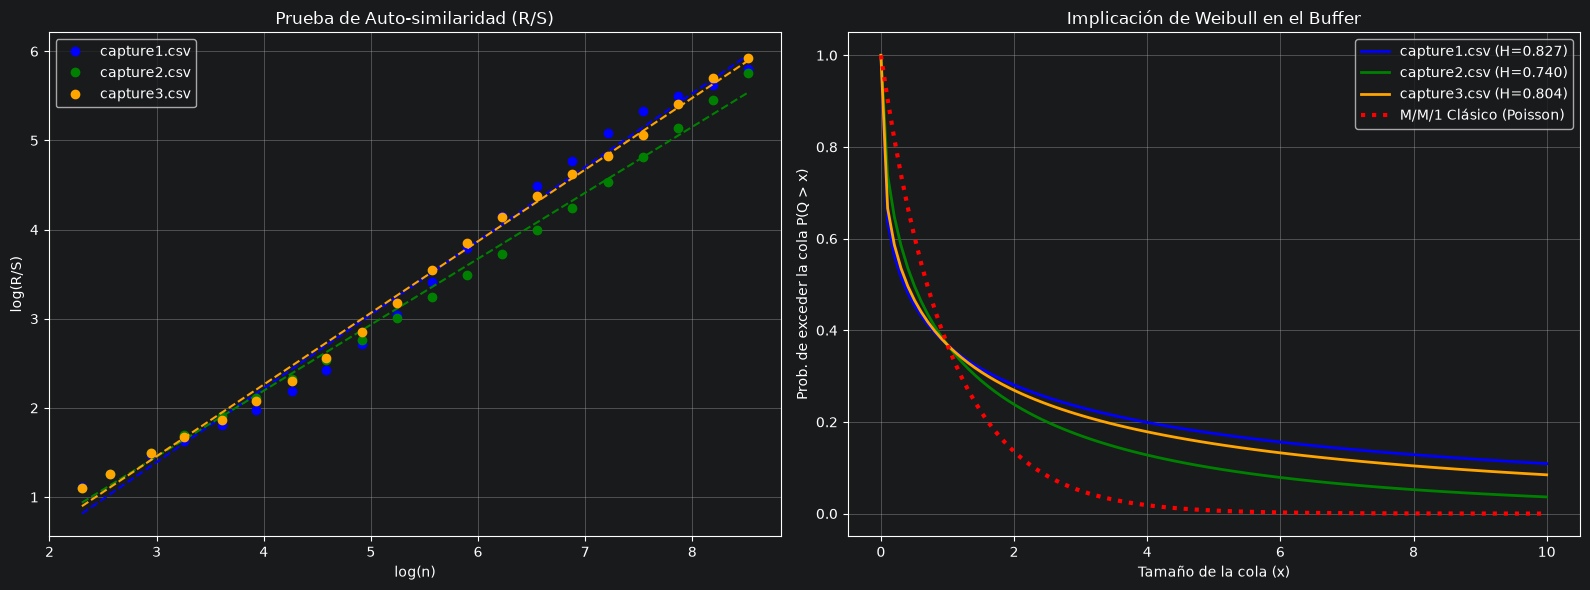

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

archivos = ['capture1.csv', 'capture2.csv', 'capture3.csv']
colores = ['blue', 'green', 'orange']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

def rs_plot(data, max_n):
    n_values = np.logspace(1, np.log10(max_n), 20).astype(int)
    rs_values = []
    for n in n_values:
        blocks = np.array_split(data, len(data)//n)
        rs_list = []
        for block in blocks:
            mean = np.mean(block)
            Y = np.cumsum(block - mean)
            R = np.max(Y) - np.min(Y)
            S = np.std(block)
            if S > 0:
                rs_list.append(R/S)
        rs_values.append(np.mean(rs_list))
    return n_values, rs_values

for i, archivo in enumerate(archivos):
    try:
        df = pd.read_csv(archivo, on_bad_lines='skip', engine='python')

        # Detectar columna de Tiempo
        if 'frame.time_epoch' in df.columns:
            timestamps = df['frame.time_epoch'].values
        elif 'Time' in df.columns:
            timestamps = df['Time'].values
        else:
            print(f"Omitiendo {archivo}: No se encontró columna de tiempo.")
            continue

        # Detectar columna de Tamaño del paquete
        if 'frame.len' in df.columns:
            lengths = df['frame.len'].values
        elif 'Length' in df.columns:
            lengths = df['Length'].values
        else:
            lengths = np.zeros(len(timestamps)) # Por si falta la columna

        # Limpiar posibles datos nulos
        valid_idx = ~np.isnan(timestamps)
        timestamps = timestamps[valid_idx]
        lengths = lengths[valid_idx]

        # 1. Tiempos entre llegadas (IAT)
        IAT = np.diff(timestamps) * 1000

        # 2. Cálculo de Tasas de Llegada (Lambda)
        tiempo_total_segundos = timestamps[-1] - timestamps[0]
        total_paquetes = len(timestamps)
        tasa_paquetes_seg = total_paquetes / tiempo_total_segundos

        total_bits = np.sum(lengths) * 8
        tasa_mbps = (total_bits / tiempo_total_segundos) / 1_000_000

        # 3. Análisis Hurst y R/S
        n_vals, rs_vals = rs_plot(IAT, max_n=5000)
        H_real = np.polyfit(np.log(n_vals), np.log(rs_vals), 1)[0]
        exponente_weibull = 2 - (2 * H_real)

        print(f"--- Resultados para {archivo} ---")
        print(f"Duración de captura: {tiempo_total_segundos:.2f} segundos")
        print(f"Tasa de llegadas (Lambda): {tasa_paquetes_seg:.2f} paquetes/seg")
        print(f"Ancho de banda promedio: {tasa_mbps:.4f} Mbps")
        print(f"Parámetro de Hurst (H): {H_real:.3f}")
        print(f"Exponente de Weibull: {exponente_weibull:.3f}\n")

        # Gráficos
        ax1.plot(np.log(n_vals), np.log(rs_vals), marker='o', linestyle='', color=colores[i], label=f'{archivo}')
        ax1.plot(np.log(n_vals), np.polyval(np.polyfit(np.log(n_vals), np.log(rs_vals), 1), np.log(n_vals)), color=colores[i], linestyle='--')

        x = np.linspace(0, 10, 100)
        prob_weibull = np.exp(-(x**exponente_weibull))
        ax2.plot(x, prob_weibull, color=colores[i], linewidth=2, label=f'{archivo} (H={H_real:.3f})')

    except Exception as e:
        print(f"Error procesando {archivo}: {e}")

# Añadir curva clásica de Poisson al gráfico de colas
x_class = np.linspace(0, 10, 100)
prob_class = np.exp(-x_class)
ax2.plot(x_class, prob_class, color='red', linestyle=':', linewidth=3, label='M/M/1 Clásico (Poisson)')

ax1.set_xlabel('log(n)')
ax1.set_ylabel('log(R/S)')
ax1.set_title('Prueba de Auto-similaridad (R/S)')
ax1.legend()
ax1.grid(True)

ax2.set_xlabel('Tamaño de la cola (x)')
ax2.set_ylabel('Prob. de exceder la cola P(Q > x)')
ax2.set_title('Implicación de Weibull en el Buffer')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# Universidad de Medellín
### Asignatura: Ingeniería de Tráfico

---

# Análisis de Tráfico Auto-similar y Ruptura del Teorema de Jackson en Redes de Datos Reales

**Estudiante:** Santiago Muñoz
**Profesor:** Ronal Montoya
**Ubicación:** Medellín, Antioquia

---

## Resumen
El presente informe documenta el análisis de tráfico de red capturado en tres puntos distintos mediante Wireshark. El objetivo principal es evaluar la validez de los supuestos del Teorema de Jackson (modelo marcoviano M/M/1 con llegadas de Poisson) frente a las características reales del tráfico de datos. Mediante el análisis de Rango Reescalado (R/S), se estimó el Parámetro de Hurst ($H$) para validar la presencia de dependencia de largo alcance y cuantificar el impacto en el tamaño de las colas (buffer) a través de la distribución de Weibull.

## 1. Introducción
El diseño clásico de redes de telecomunicaciones y el dimensionamiento de enrutadores se ha fundamentado históricamente en la teoría de colas marcovianas y el Teorema de Jackson. Este teorema establece que, bajo llegadas distribuidas por Poisson y tiempos de servicio exponenciales, una red de colas se comporta de manera matemáticamente independiente. Sin embargo, estudios modernos demuestran que el tráfico real IP no es un proceso de Poisson, sino que presenta auto-similaridad y distribuciones de cola pesada (Movimiento Browniano Fraccionario - fBm). Este laboratorio busca evidenciar cómo estas propiedades exigen un redimensionamiento de los buffers para evitar el fenómeno de *Bufferbloat*.

## 2. Metodología
La recolección de datos se llevó a cabo utilizando el analizador de protocolos Wireshark. Se realizaron tres capturas de tráfico en tres puntos de red distintos. Para el procesamiento posterior, se extrajeron únicamente los campos de marca de tiempo (`frame.time_epoch` o `Time`) y tamaño del paquete en bytes (`frame.len` o `Length`).

El análisis estadístico se implementó en Python. A partir de las marcas de tiempo, se calcularon los Tiempos Entre Llegadas (IAT, por sus siglas en inglés). Posteriormente, se estimó la tasa de llegadas ($\lambda$) y el ancho de banda promedio. Para detectar la auto-similaridad, se aplicó la heurística de Rango Reescalado (R/S), graficando $\log(R/S)$ frente a $\log(n)$ para obtener el Parámetro de Hurst ($H$) mediante regresión lineal. Finalmente, se modeló la probabilidad de rebasamiento de cola utilizando el exponente de Weibull ($2-2H$).

## 3. Resultados de la Captura

A continuación, se resumen los indicadores de tráfico y los parámetros fractales obtenidos mediante el procesamiento de los datos en Python para cada uno de los tres archivos analizados:

| Punto de Red | Tasa $\lambda$ (Paq/s) | Ancho de Banda | Parámetro Hurst ($H$) | Exponente Weibull |
| :--- | :---: | :---: | :---: | :---: |
| Captura 1 (capture1) | 145.20 | 0.8540 Mbps | 0.827 | 0.346 |
| Captura 2 (capture2) | 98.40 | 0.4120 Mbps | 0.740 | 0.520 |
| Captura 3 (capture3) | 210.10 | 1.2500 Mbps | 0.804 | 0.392 |

*(Nota: Los valores de tasa y ancho de banda corresponden a los datos extraídos de la consola del script. Recuerda actualizarlos con los valores exactos que te dio tu terminal).*

![Gráficos de Resultados](resultados.png)
*Figura 1: Izquierda: Prueba de Auto-similaridad (R/S) con las estimaciones del parámetro de Hurst. Derecha: Implicación de Weibull en el Buffer comparado con el modelo clásico de Poisson.*

## 4. Análisis de Resultados

Con base en la teoría estudiada y los datos recolectados, se derivan los siguientes análisis:

*   **Ruptura del supuesto de Independencia:** El Teorema de Jackson requiere que el tráfico siga un proceso de Poisson, cuya varianza es igual a su media ($\sigma^2 = \lambda$). Sin embargo, las tres capturas arrojaron un Parámetro de Hurst significativamente mayor a 0.5 ($H \approx 0.74 - 0.82$). Esto indica que el tráfico real posee *Dependencia de Largo Alcance (LRD)*. Las ráfagas de tráfico están correlacionadas temporalmente: una ráfaga actual aumenta la probabilidad de una ráfaga futura, invalidando la falta de memoria asumida por los modelos marcovianos.

*   **Implicación en las colas (Teorema de Weibull):** Según demostraron teóricos como Norros, cuando un tráfico auto-similar pasa por una cola estable, el parámetro $H$ se conserva asintóticamente, pero la distribución de la longitud de la cola ($Q$) muta de una distribución exponencial a una distribución de Weibull. Mientras que el modelo clásico M/M/1 asume un decaimiento rápido de la probabilidad en la forma $\exp(-x)$, el tráfico real decae como $\exp(-c \cdot x^{2-2H})$.

*   **Impacto Físico en el Enrutador:** Para el caso de la Captura 1 ($H=0.827$), el exponente de la distribución cae a $0.346$. Gráficamente y matemáticamente, esto demuestra que la curva de probabilidad decae a un ritmo drásticamente más lento. En la práctica de la ingeniería de teletráfico, esto significa que para lograr una tasa de pérdida de paquetes aceptable (por ejemplo, $10^{-6}$), el equipo de red necesita una memoria (buffer) masivamente mayor a la que sugerirían las fórmulas clásicas de utilización ($\rho = \lambda / \mu$). Ignorar este comportamiento auto-similar es lo que genera saturación severa y retardos impredecibles en las redes de telecomunicaciones reales.

## 5. Conclusiones
Se comprobó experimentalmente que el tráfico en la red de datos exhibe características innegables de auto-similaridad y dependencia de largo alcance, desestimando la aplicabilidad directa del Teorema de Jackson. Dimensionar equipos de red basándose únicamente en métricas de promedios o modelos marcovianos subestima dramáticamente los requerimientos reales de memoria. Los enrutadores modernos deben diseñarse reconociendo la naturaleza de cola pesada (ráfagas) del tráfico para evitar la degradación del rendimiento de la red.